In [25]:
import os
import glob
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configurazione stile grafici
sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["figure.dpi"] = 150

In [26]:
EXP_BASE_DIR = "experiments/backbone_evaluation"

# Trova tutte le cartelle results_*
results_dirs = sorted(glob.glob(os.path.join(EXP_BASE_DIR, "results_*")))

dfs = []
raw_feature_names = []

# Primo passaggio: raccoglie tutti i dati e i nomi univoci dei dataset
for r_dir in results_dirs:
    csv_path = os.path.join(r_dir, "results.csv")
    json_path = os.path.join(r_dir, "metadata.json")
    
    if os.path.exists(csv_path):
        df = pd.read_csv(csv_path)
        exp_id = os.path.basename(r_dir).replace("results_", "")
        
        feature_name = exp_id
        pooling = "N/A"
        if os.path.exists(json_path):
            with open(json_path, mode="r", encoding="utf-8") as f:
                meta = json.load(f)
                raw_name = meta.get("feature_name", exp_id)
                feature_name = raw_name.replace("train__", "").replace(".pt", "")
                pooling = meta.get("pooling", "N/A")
        
        df["experiment_id"] = exp_id
        df["feature_name"] = feature_name
        df["pooling"] = pooling
        dfs.append(df)
        
        if feature_name not in raw_feature_names:
            raw_feature_names.append(feature_name)

df_all = pd.concat(dfs, ignore_index=True)

# Crea la mappatura univoca: Feature Name -> Lettera (A, B, C, ...)
unique_features = sorted(df_all["feature_name"].unique())
letter_map = {name: chr(65 + i) for i, name in enumerate(unique_features)}

df_all["dataset_label"] = df_all["feature_name"].map(letter_map)
df_all["accuracy_mean"] = df_all["accuracy_mean"].astype(float)
df_all["macro_f1_mean"] = df_all["macro_f1_mean"].astype(float)

# Stampa Legenda Mappatura
print("=" * 80)
print("LEGENDA DATASET (MAPPATURA LETTERE -> NOMI COMPLETI)")
print("=" * 80)
for name, letter in letter_map.items():
    print(f"  Dataset [{letter}] ──► {name}")
print("=" * 80)

display(df_all[["dataset_label", "phase", "prober_name", "accuracy_mean", "macro_f1_mean", "pooling"]].head(12))

LEGENDA DATASET (MAPPATURA LETTERE -> NOMI COMPLETI)
  Dataset [A] ──► x3dl__trackernone__edgedense16s100__letterbox312__rgb__4cacfaa4
  Dataset [B] ──► x3dl__trackernone__edgedense16s100__stretch312__rgb__9f63f404
  Dataset [C] ──► x3dl__trackernone__edgedense32s100__stretch312__rgb__324d121f
  Dataset [D] ──► x3dl__trackernone__legacyuniform16__letterbox312__rgb__489f0579
  Dataset [E] ──► x3dl__trackernone__legacyuniform16__stretch312__rgb__3ccd4dc1
  Dataset [F] ──► x3dl__trackernone__preserveall__stretch312__rgb__d97b3956


,dataset_label,phase,prober_name,accuracy_mean,macro_f1_mean,pooling
0,A,p1,MLP_L1_H256,0.791852,0.774051,mean
1,A,p1,MLP_L2_H256,0.811481,0.803311,mean
2,A,p1,MLP_L3_H256,0.801852,0.795919,mean
3,A,p1,kNN_Probe_k3_cosine,0.768519,0.744055,mean
4,A,p2,MLP_L1_H256,0.680000,0.640952,mean
5,A,p2,MLP_L2_H256,0.673846,0.639862,mean
6,A,p2,MLP_L3_H256,0.627692,0.595316,mean
7,A,p2,kNN_Probe_k3_cosine,0.538462,0.515737,mean
8,A,p3,MLP_L1_H256,0.689231,0.683247,mean
9,A,p3,MLP_L2_H256,0.661538,0.658612,mean


In [27]:
# Vista pivot per confrontare le F1-Macro tra le lettere assegnate ai dataset
pivot_f1 = df_all.pivot_table(
    index=["phase", "prober_name"],
    columns="dataset_label",
    values="macro_f1_mean"
)

letter_cols = [c for c in pivot_f1.columns]
pivot_f1["Mean F1"] = pivot_f1[letter_cols].mean(axis=1)

print("=== CONFRONTO MACRO F1-SCORE PER DATASET ===")
display(pivot_f1.style.background_gradient(cmap="YlGn", subset=letter_cols + ["Mean F1"]))

=== CONFRONTO MACRO F1-SCORE PER DATASET ===


In [ ]:
# Grafico a barre con legende e assi estremamente leggibili
g = sns.catplot(
    data=df_all,
    kind="bar",
    x="prober_name",
    y="macro_f1_mean",
    hue="dataset_label",
    col="phase",
    aspect=1.2,
    height=4,
    palette="tab10"
)

g.set_axis_labels("Prober", "Macro F1-Score")
g.set_titles("Fase: {col_name}")
g.set_xticklabels(rotation=30, ha="right")
g._legend.set_title("Dataset")
g.fig.subplots_adjust(top=0.8)
g.fig.suptitle("Confronto Performance Probing per Dataset (A, B, C...)", fontsize=14, fontweight="bold")

plt.show()

ValueError: Could not interpret value `macro f1-score` for `y`. An entry with this name does not appear in `data`.

=== MIGLIOR PROBER PER DATASET E FASE ===


,dataset_label,feature_name,phase,prober_name,accuracy,macro f1-score
0,C,x3dl__trackernone__edgedense32s100__stretch312...,flat,MLP_L3_H256,0.742593,0.524679
1,E,x3dl__trackernone__legacyuniform16__stretch312...,flat,MLP_L2_H256,0.703704,0.502271
2,B,x3dl__trackernone__edgedense16s100__stretch312...,flat,MLP_L1_H256,0.692593,0.477655
3,F,x3dl__trackernone__preserveall__stretch312__rg...,flat,MLP_L1_H256,0.737037,0.461767
4,A,x3dl__trackernone__edgedense16s100__letterbox3...,flat,MLP_L2_H256,0.692593,0.407370
5,D,x3dl__trackernone__legacyuniform16__letterbox3...,flat,MLP_L2_H256,0.616667,0.364937
6,C,x3dl__trackernone__edgedense32s100__stretch312...,p1,MLP_L2_H256,0.848148,0.860384
7,B,x3dl__trackernone__edgedense16s100__stretch312...,p1,MLP_L2_H256,0.833333,0.842089
8,E,x3dl__trackernone__legacyuniform16__stretch312...,p1,MLP_L1_H256,0.800000,0.810975
9,A,x3dl__trackernone__edgedense16s100__letterbox3...,p1,MLP_L3_H256,0.807407,0.808660


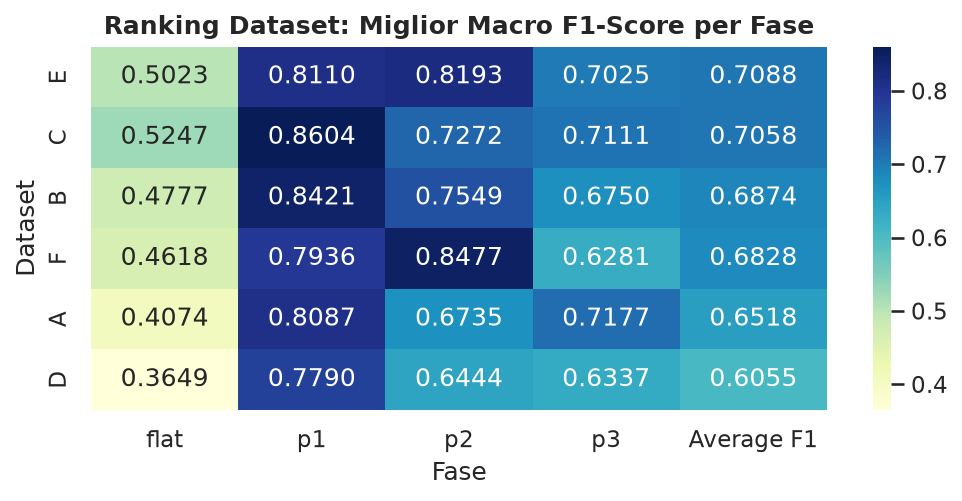

In [ ]:
# Identifica il miglior prober per ogni fase e dataset
best_per_phase = df_all.loc[df_all.groupby(["dataset_label", "phase"])["macro f1-score"].idxmax()]

print("=== MIGLIOR PROBER PER DATASET E FASE ===")
display(
    best_per_phase[["dataset_label", "feature_name", "phase", "prober_name", "accuracy", "macro f1-score"]]
    .sort_values(by=["phase", "macro f1-score"], ascending=[True, False])
    .reset_index(drop=True)
)

# Heatmap sintetica con le sole lettere sui diversi assi
best_pivot = best_per_phase.pivot(index="dataset_label", columns="phase", values="macro f1-score")
best_pivot["Average F1"] = best_pivot.mean(axis=1)
best_pivot = best_pivot.sort_values(by="Average F1", ascending=False)

plt.figure(figsize=(7, 3.5))
sns.heatmap(best_pivot, annot=True, fmt=".4f", cmap="YlGnBu", cbar=True)
plt.title("Ranking Dataset: Miglior Macro F1-Score per Fase", fontsize=12, fontweight="bold")
plt.ylabel("Dataset")
plt.xlabel("Fase")
plt.tight_layout()
plt.show()